📁 输出目录: figures
🔍 可用字体文件路径:
  C:\Windows\Fonts\calibril.ttf
  C:\Windows\Fonts\IQYHT-Bold.ttf
  C:\Windows\Fonts\framd.ttf
  C:\Windows\Fonts\micross.ttf
  C:\Windows\Fonts\gadugib.ttf
  C:\Windows\Fonts\segoeuii.ttf
  C:\Windows\Fonts\CASIO ClassWiz.ttf
  C:\Windows\Fonts\ariblk.ttf
  C:\Windows\Fonts\Candarai.ttf
  C:\Windows\Fonts\mingliub.ttc
  C:\Windows\Fonts\HPSimplified_Rg.ttf
  C:\Windows\Fonts\mvboli.ttf
  C:\Windows\Fonts\malgunbd.ttf
  C:\Windows\Fonts\msjhbd.ttc
  C:\Windows\Fonts\impact.ttf
  C:\Windows\Fonts\HPSimplified_It.ttf
  C:\Windows\Fonts\Candarali.ttf
  C:\Windows\Fonts\symbol.ttf
  C:\Windows\Fonts\segoepr.ttf
  C:\Windows\Fonts\YuGothM.ttc
  C:\Windows\Fonts\trebucbi.ttf
  C:\Windows\Fonts\ntailub.ttf
  C:\Windows\Fonts\monbaiti.ttf
  C:\Windows\Fonts\trebuc.ttf
  C:\Windows\Fonts\NirmalaS.ttf
  C:\Windows\Fonts\courbd.ttf
  C:\Windows\Fonts\ariali.ttf
  C:\Windows\Fonts\calibri.ttf
  C:\ProgramData\kingsoft\office6\KingsoftUE\KingsoftUE.ttf
  C:\Windows\Fonts

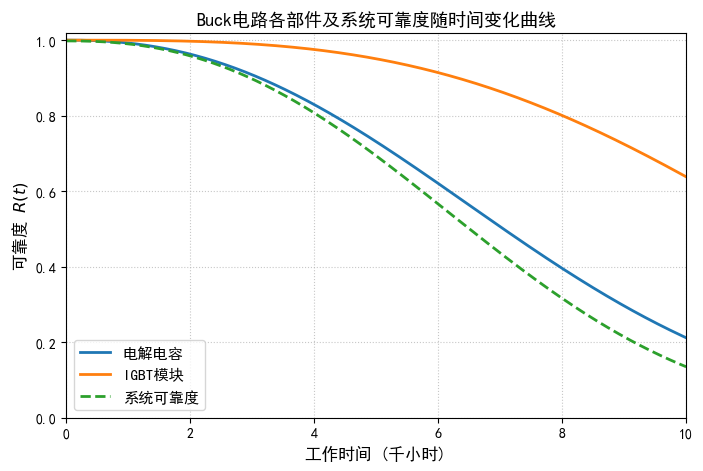

In [4]:
# generate_plot.py
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib import font_manager

# ==================== 参数设置 ====================
t = np.linspace(0, 10000, 500)

# 电解电容参数
m1, eta1 = 2.31, 8264
R_cap = np.exp(-(t / eta1) ** m1)

# IGBT 模块参数
m2, eta2 = 3.15, 12890
R_igbt = np.exp(-(t / eta2) ** m2)

# 系统可靠度（串联）
R_sys = R_cap * R_igbt * 0.999 * 0.999

# ==================== 创建输出目录 ====================
output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)
print(f"📁 输出目录: {output_dir}")

# ==================== 查找可用字体文件（路径）====================
# findSystemFonts 返回的是文件路径列表（字符串）
available_font_paths = font_manager.findSystemFonts(fontpaths=None, fontext='ttf')
print("🔍 可用字体文件路径:")
for path in available_font_paths:
    print(f"  {path}")

# ==================== 尝试加载常见中文字体 ====================
common_chinese_fonts = [
    'SimHei',           # 黑体
    'Microsoft YaHei',  # 微软雅黑
    'FangSong',         # 楷体
    'KaiTi',            # 楷体
    'Arial Unicode MS'  # 支持Unicode的西文字体
]

selected_font = None
for font_name in common_chinese_fonts:
    # 尝试查找该字体是否在系统中
    for path in available_font_paths:
        if font_name.lower() in path.lower():
            selected_font = font_name
            break
    if selected_font:
        break

if selected_font is None:
    print("❌ 未找到任何常用中文字体！将使用默认字体。")
else:
    print(f"✅ 已选择中文字体: {selected_font}")
    plt.rcParams['font.sans-serif'] = [selected_font]
    plt.rcParams['axes.unicode_minus'] = False  # 正确显示负号

# ==================== 绘图 ====================
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t / 1000, R_cap, label='电解电容', linewidth=2, color='tab:blue')
ax.plot(t / 1000, R_igbt, label='IGBT模块', linewidth=2, color='tab:orange')
ax.plot(t / 1000, R_sys, label='系统可靠度', linewidth=2, linestyle='--', color='tab:green')

ax.set_xlabel('工作时间 (千小时)', fontsize=12)
ax.set_ylabel('可靠度 $R(t)$', fontsize=12)
ax.set_title('Buck电路各部件及系统可靠度随时间变化曲线', fontsize=13)
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.02)
ax.set_xlim(0, 10)

# ==================== 保存为 PDF ====================
output_path = os.path.join(output_dir, "reliability_curve.pdf")
plt.savefig(output_path, bbox_inches='tight', dpi=300, format='pdf')
print(f"✅ 图表已成功保存至: {output_path}")

# 显示图像（调试用）
plt.show()